Title: Contribution_RL_Days_NM.ipynb

Purpose: Look how the different components (wind, solar, demand) contribute to the residual load days

Author: Onno Nennecke on 03.09.2025 Modified: 27.02.2026

Input data: 

- Combined model output: model_output_all.nc
    - This file lies here: /climca/people/onennecke/model_output/not_bias_corrected/model_output_all.nc

Output data:

- Plot: 
    - This file lies here: /home/onennecke/Code/Figures/

In [1]:
# Importing libraries
import xarray as xr
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors


In [2]:
path = '/climca/people/onennecke/model_output/not_bias_corrected/model_output_all.nc'
files = [path]

ds = xr.open_dataset(path)

ts_datasets = ds.where((ds.ESM_run != 'ERA5_hist_wwd') & (ds.ESM_run != 'SMARD_hist'),drop=True)
ts_datasets.load()


<xarray.Dataset> Size: 59MB
Dimensions:        (ESM_run: 193, time: 3650)
Coordinates:
    crs            int64 8B 4326
    gridtype       <U6 24B 'lonlat'
  * time           (time) datetime64[ns] 29kB 2015-01-01 ... 2024-12-31
    ESM            (ESM_run) <U13 10kB 'ACCESS-CM2' ... 'UKESM1-0-LL'
    run            (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r8i1p1f2'
  * ESM_run        (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'UKESM1-0-LL...
    country        float64 8B 9.0
    period         (ESM_run) <U4 3kB 'week' 'week' 'week' ... 'week' 'week'
    doy            (time) int64 29kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
Data variables:
    temp           (ESM_run, time) float64 6MB 2.862 -0.3492 ... -8.134 -9.41
    demand         (ESM_run, time) float64 6MB 1.485e+03 1.524e+03 ... 1.636e+03
    sfcWind        (ESM_run, time) float64 6MB 8.056 6.177 6.451 ... 3.01 4.735
    rsds           (ESM_run, time) float32 3MB 13.75 24.11 38.15 ... 38.66 48.7
    tas            (ESM_run, time) float32 3MB 2.114 -0.7924 ... -7.047 -8.388
    tasmax         (ESM_run, time) float32 3MB 4.033 0.7523 ... -3.341 -4.217
    wind_off_prod  (ESM_run, time) float64 6MB 122.3 158.7 129.4 ... 9.998 79.37
    wind_on_prod   (ESM_run, time) float64 6MB 731.3 532.7 450.6 ... 31.44 148.9
    solar_prod     (ESM_run, time) float64 6MB 21.42 39.42 66.29 ... 71.95 87.86
    total_prod     (ESM_run, time) float64 6MB 875.0 730.8 646.3 ... 113.4 316.1
    Netto          (ESM_run, time) float64 6MB -609.5 -793.4 ... -1.32e+03
    Residual_load  (ESM_run, time) float64 6MB 609.5 793.4 ... 1.32e+03

In [3]:
# --- 2) Extract the three time series arrays [ESM_run, time] ---
# wind = ts_datasets['wind_off_prod'] + ts_datasets['wind_on_prod']
solar = ts_datasets['solar_prod']
total = ts_datasets['total_prod']
# demand = ts_datasets['demand']
res_load = ts_datasets['Residual_load']
wind = ts_datasets['wind_off_prod'] + ts_datasets['wind_on_prod']
# solar = ts_datasets['solar_prod']
# total = ts_datasets['total_prod']
demand = ts_datasets['demand']
# res_load = ts_datasets['Residual_load']

# Thresholds
wind_thresh = np.quantile(wind.values.flatten(), 0.05)
solar_thresh = np.quantile(solar.values.flatten(), 0.05)
total_thresh = np.quantile(total.values.flatten(), 0.05)
demand_thresh = np.quantile(demand.values.flatten(), 0.95)
res_load_thresh = np.quantile(res_load.values.flatten(), 0.95)
print(res_load_thresh)
# --- 3) Pull out the doy coordinate for x-axis ---
x = ts_datasets['doy']

# --- 4) Compute the mean winter cycle (averaged over runs & winters) ---
# mean_wind  = wind.groupby(x).mean(dim=['ESM_run','time'])
# mean_solar = solar.groupby(x).mean(dim=['ESM_run','time'])
# mean_total = total.groupby(x).mean(dim=['ESM_run','time'])
# mean_demand = demand.groupby(x).mean(dim=['ESM_run','time'])
# mean_res_load = res_load.groupby(x).mean(dim=['ESM_run','time'])


1319.138650687668


In [4]:
# Extreme event days:
extreme_res_load = ts_datasets.where(ts_datasets['Residual_load'] > res_load_thresh)
extreme_res_load

<xarray.Dataset> Size: 59MB
Dimensions:        (ESM_run: 193, time: 3650)
Coordinates:
    crs            int64 8B 4326
    gridtype       <U6 24B 'lonlat'
  * time           (time) datetime64[ns] 29kB 2015-01-01 ... 2024-12-31
    ESM            (ESM_run) <U13 10kB 'ACCESS-CM2' ... 'UKESM1-0-LL'
    run            (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r8i1p1f2'
  * ESM_run        (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'UKESM1-0-LL...
    country        float64 8B 9.0
    period         (ESM_run) <U4 3kB 'week' 'week' 'week' ... 'week' 'week'
    doy            (time) int64 29kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
Data variables:
    temp           (ESM_run, time) float64 6MB nan nan nan ... nan -8.134 -9.41
    demand         (ESM_run, time) float64 6MB nan nan ... 1.62e+03 1.636e+03
    sfcWind        (ESM_run, time) float64 6MB nan nan nan ... nan 3.01 4.735
    rsds           (ESM_run, time) float32 3MB nan nan nan ... nan 38.66 48.7
    tas            (ESM_run, time) float32 3MB nan nan nan ... nan -7.047 -8.388
    tasmax         (ESM_run, time) float32 3MB nan nan nan ... nan -3.341 -4.217
    wind_off_prod  (ESM_run, time) float64 6MB nan nan nan ... nan 9.998 79.37
    wind_on_prod   (ESM_run, time) float64 6MB nan nan nan ... nan 31.44 148.9
    solar_prod     (ESM_run, time) float64 6MB nan nan nan ... nan 71.95 87.86
    total_prod     (ESM_run, time) float64 6MB nan nan nan ... nan 113.4 316.1
    Netto          (ESM_run, time) float64 6MB nan nan ... -1.507e+03 -1.32e+03
    Residual_load  (ESM_run, time) float64 6MB nan nan ... 1.507e+03 1.32e+03

In [5]:
# 1) Convert dataset to a long DataFrame
df = ts_datasets.to_dataframe().reset_index()   # columns will include ESM_run, time, ESM, run, variables...

df['winter'] = np.where(df['time'].dt.month.isin([10, 11, 12, 1, 2, 3]), 1, 0)

df['wind_total'] = df['wind_off_prod'] + df['wind_on_prod']

# Filter by the threshold
df_winter = df[df['winter'] == 1]

# Drop any remaining rows with NaNs across any column
df_winter = df_winter.dropna(how='any').reset_index(drop=True)

# Filter by the threshold
df_filtered = df[df['Residual_load'] > res_load_thresh]

# Drop any remaining rows with NaNs across any column
df_filtered = df_filtered.dropna(how='any').reset_index(drop=True)


# df_filtered is now a tidy pandas DataFrame: one row per selected event
print(df_filtered.shape)
df_filtered.head()


(35223, 23)


,ESM_run,time,temp,demand,sfcWind,rsds,tas,tasmax,wind_off_prod,wind_on_prod,...,Residual_load,crs,gridtype,ESM,run,country,period,doy,winter,wind_total
0,ACCESS-CM2_r1i1p1f1,2015-01-05,0.245598,1516.886409,4.147174,21.248137,0.787202,1.800007,50.364626,88.540153,...,1347.755832,4326,lonlat,ACCESS-CM2,r1i1p1f1,9.0,week,5,1,138.904779
1,ACCESS-CM2_r1i1p1f1,2015-01-07,-3.086905,1557.932764,4.904704,27.715582,-2.206280,-0.751457,28.271873,148.532826,...,1333.134503,4326,lonlat,ACCESS-CM2,r1i1p1f1,9.0,week,7,1,176.804699
2,ACCESS-CM2_r1i1p1f1,2015-01-08,-3.234493,1559.748740,3.830855,30.455936,-2.128153,-0.627887,32.262058,73.867000,...,1395.107358,4326,lonlat,ACCESS-CM2,r1i1p1f1,9.0,week,8,1,106.129058
3,ACCESS-CM2_r1i1p1f1,2015-01-18,1.290212,1503.988486,2.607071,29.728300,1.512397,2.677035,16.778485,28.005361,...,1409.547842,4326,lonlat,ACCESS-CM2,r1i1p1f1,9.0,week,18,1,44.783847
4,ACCESS-CM2_r1i1p1f1,2015-01-19,0.318840,1515.982819,3.103404,33.742901,0.572515,1.431716,11.385196,46.861549,...,1403.974418,4326,lonlat,ACCESS-CM2,r1i1p1f1,9.0,week,19,1,58.246745


In [6]:
df_summer = df[df['winter'] == 0]
df_summer = df_summer.dropna(how='any').reset_index(drop=True)

In [7]:
# Filter by the threshold
df_reverse_filtered = df[df['Residual_load'] < res_load_thresh]

# Drop any remaining rows with NaNs across any column
df_reverse_filtered = df_reverse_filtered.dropna(how='any').reset_index(drop=True)

In [8]:
print('All Demand min: ', df['demand'].min())
print('All Demand max: ', df['demand'].max())
print('All Demand range: ', df['demand'].max() - df['demand'].min())

print('VRES days Demand min: ', df_filtered['demand'].min())
print('VRES days Demand max: ', df_filtered['demand'].max())
print('VRES days Demand range: ', df_filtered['demand'].max() - df_filtered['demand'].min())

print('Demand VRES days % of All:', (df['demand'].max() - df_filtered['demand'].min()) / (df['demand'].max() - df['demand'].min()) * 100, '\n')

print('All Solar production min: ', df['solar_prod'].min())
print('All Solar production max: ', df['solar_prod'].max())
print('All Solar production range: ', df['solar_prod'].max() - df['solar_prod'].min())

print('VRES days Solar production min: ', df_filtered['solar_prod'].min())
print('VRES days Solar production max: ', df_filtered['solar_prod'].max())
print('VRES days Solar production range: ', df_filtered['solar_prod'].max() - df_filtered['solar_prod'].min())

print('Solar VRES days % of All:', df_filtered['solar_prod'].max() / df['solar_prod'].max() * 100, '\n')

print('All Wind production min: ', df['wind_total'].min())
print('All Wind production max: ', df['wind_total'].max())
print('All Wind production range: ', df['wind_total'].max() - df['wind_total'].min())

print('VRES days Wind production min: ', df_filtered['wind_total'].min())
print('VRES days Wind production max: ', df_filtered['wind_total'].max())
print('VRES days Wind production range: ', df_filtered['wind_total'].max() - df_filtered['wind_total'].min())

print('Wind VRES days % of All:', df_filtered['wind_total'].max() / df['wind_total'].max() * 100, '\n')

All Demand min:  1320.5014457353493
All Demand max:  1702.5083202511773
All Demand range:  382.00687451582803
VRES days Demand min:  1366.4885372128838
VRES days Demand max:  1702.5083202511773
VRES days Demand range:  336.01978303829355
Demand VRES days % of All: 87.96171102003845 

All Solar production min:  5.104936682458522
All Solar production max:  563.6943436228736
All Solar production range:  558.5894069404151
VRES days Solar production min:  7.821207919474142
VRES days Solar production max:  247.39570618673721
VRES days Solar production range:  239.57449826726307
Solar VRES days % of All: 43.88827189514101 

All Wind production min:  0.9245682655023042
All Wind production max:  1743.0216004079998
All Wind production range:  1742.0970321424975
VRES days Wind production min:  1.2882841257408628
VRES days Wind production max:  286.6837689741022
VRES days Wind production range:  285.3954848483613
Wind VRES days % of All: 16.44751670931653 



In [9]:
print('Solar all:', df['solar_prod'].max())
print('Wind all:', df['wind_total'].max())
print('Demand all:', df['demand'].min())

print('Solar VRES days:', df_filtered['solar_prod'].max())
print('Wind VRES days:', df_filtered['wind_total'].max())
print('Demand VRES days:', df_filtered['demand'].min())

print('Solar Winter:', df_winter['solar_prod'].max())
print('Wind Winter:', df_winter['wind_total'].max())
print('Demand Winter:', df_winter['demand'].min())

# Calculate percentage of Max VRES days compared to all
print('Solar VRES days % of All:', df_filtered['solar_prod'].max() / df['solar_prod'].max() * 100)
print('Wind VRES days % of All:', df_filtered['wind_total'].max() / df['wind_total'].max() * 100)
print('Demand VRES days % of All:', df_filtered['demand'].min() / df['demand'].min() * 100)

Solar all: 563.6943436228736
Wind all: 1743.0216004079998
Demand all: 1320.5014457353493
Solar VRES days: 247.39570618673721
Wind VRES days: 286.6837689741022
Demand VRES days: 1366.4885372128838
Solar Winter: 376.9775840941579
Wind Winter: 1743.0216004079998
Demand Winter: 1320.5014458189348
Solar VRES days % of All: 43.88827189514101
Wind VRES days % of All: 16.44751670931653
Demand VRES days % of All: 103.48254760538529


### Correlations between prod, demand and RL

All Days - Wind production: Corr=-0.82, R²=0.67
All Days - Solar production: Corr=-0.16, R²=0.03
All Days - Demand: Corr=0.24, R²=0.06
Winter Days - Wind production: Corr=-0.97, R²=0.94
Winter Days - Solar production: Corr=0.08, R²=0.01
Winter Days - Demand: Corr=0.20, R²=0.04
VRES Days - Wind production: Corr=-0.39, R²=0.15
VRES Days - Solar production: Corr=-0.13, R²=0.02
VRES Days - Demand: Corr=0.44, R²=0.19


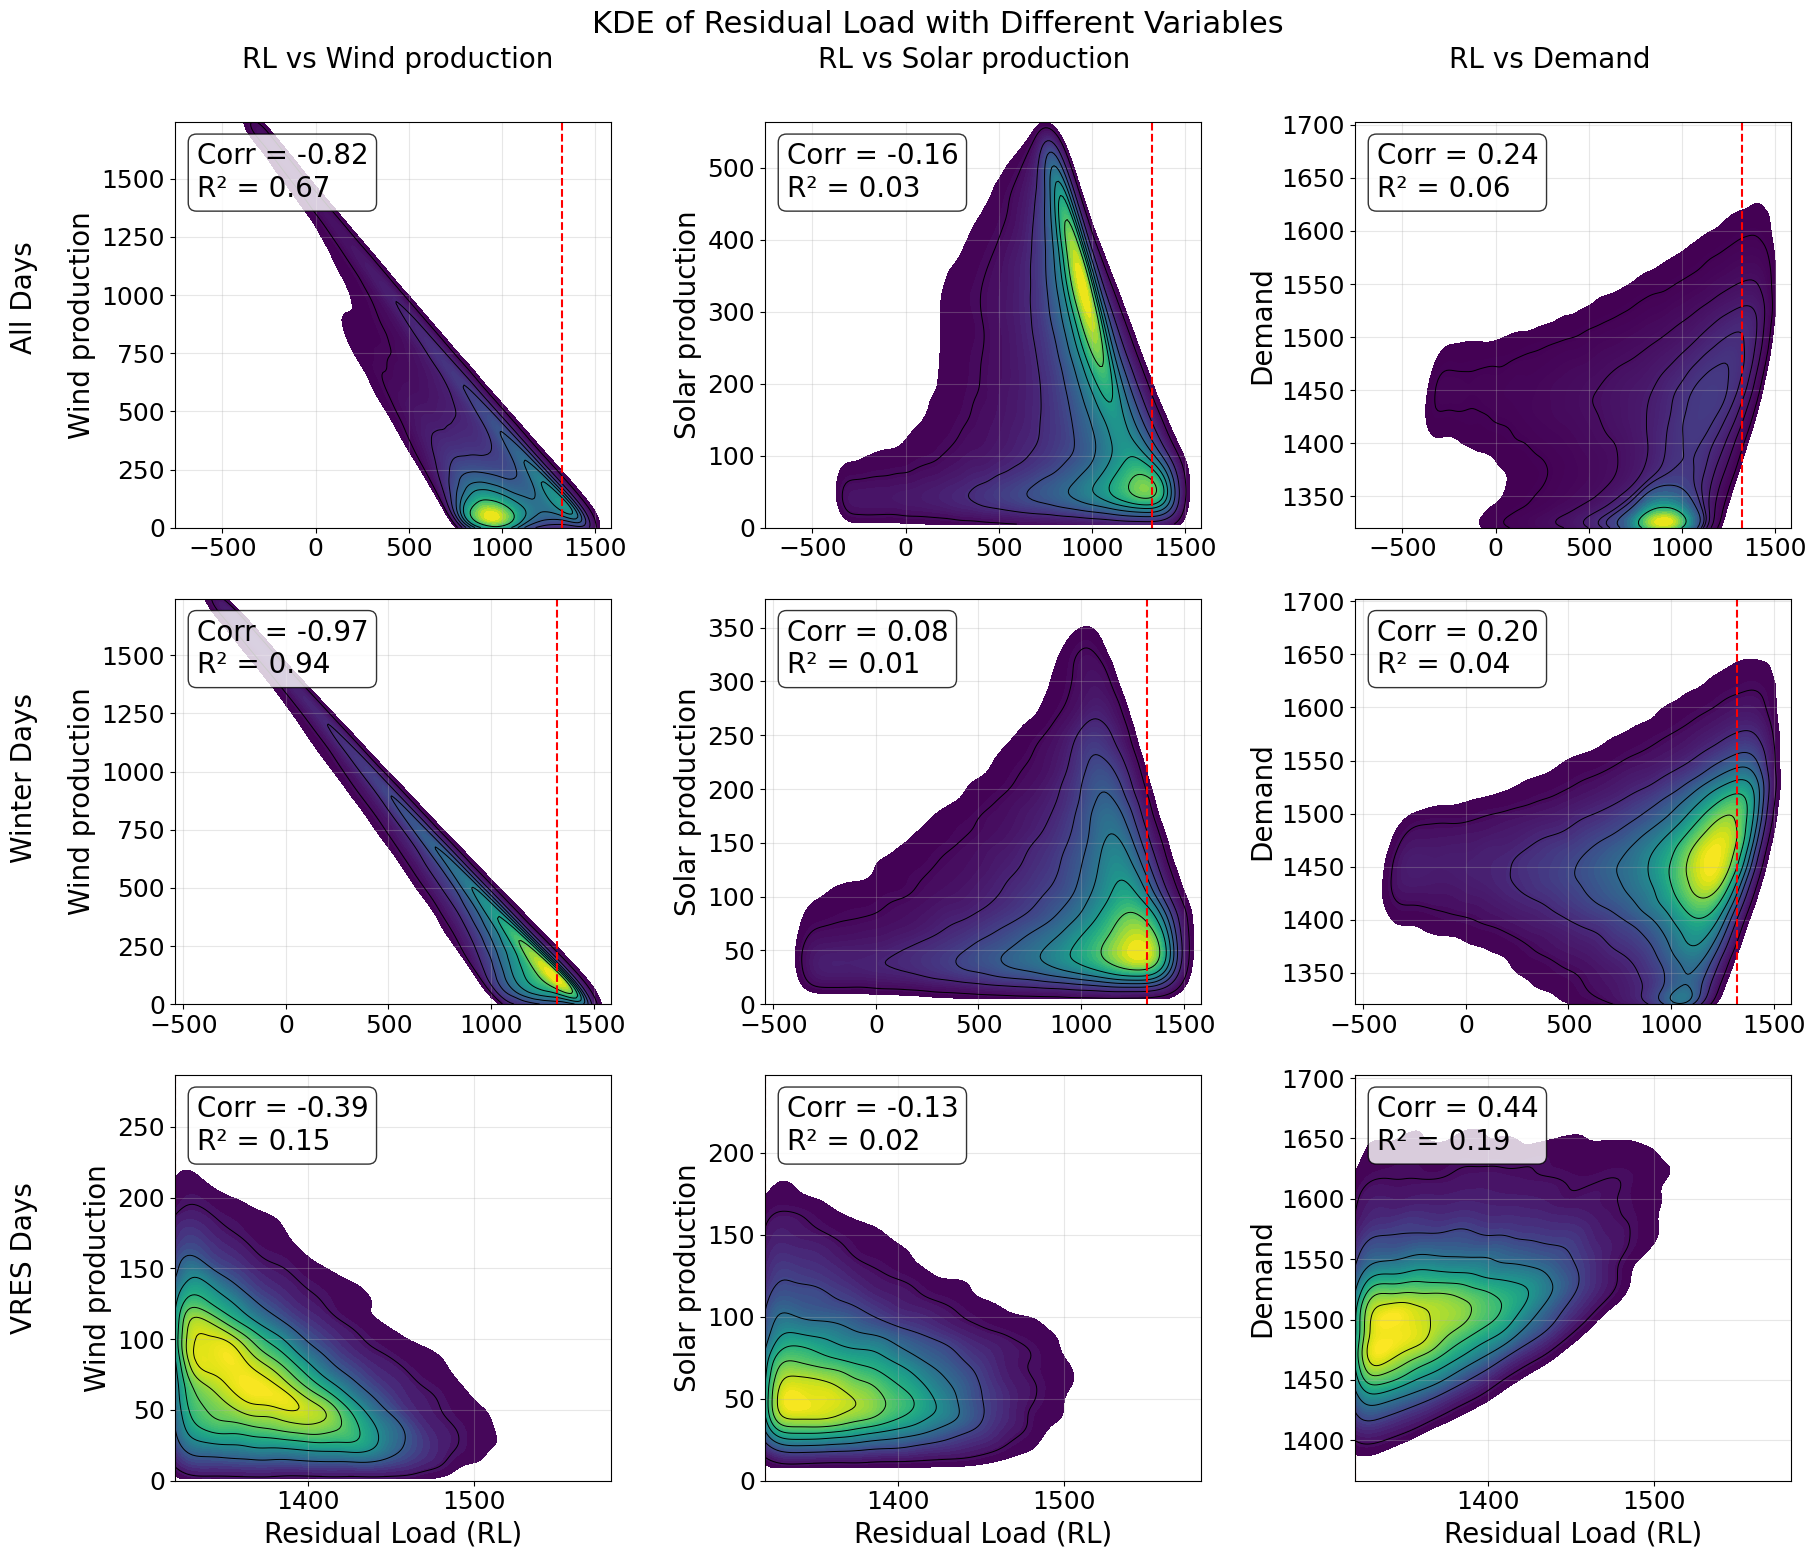

In [ ]:
# Takes 80 minuntes to run :(

# make text bigger (global)
mpl.rcParams.update({
    'font.size': 16+4,
    'axes.titlesize': 18+4,
    'axes.labelsize': 16+4,
    'xtick.labelsize': 14+4,
    'ytick.labelsize': 14+4,
    'legend.fontsize': 16+4,
    'figure.titlesize': 18+4,
})

# Define datasets and variables
datasets = {
    'All Days': df,
    'Winter Days': df_winter,
    'VRES Days': df_filtered
}

variables = {
    'wind_total': 'Wind production',
    'solar_prod': 'Solar production',
    'demand': 'Demand'
}

# Create subplot grid
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
fig.suptitle('KDE of Residual Load with Different Variables')


# Add row titles (dataset names)
for row_idx, (dataset_name, _) in enumerate(datasets.items()):
    fig.text(
        0,  # x-position (left of the first column)
        0.8 - row_idx * 0.3,  # y-position (adjust based on row)
        dataset_name,
        va='center',
        ha='right',
        # fontsize=14,
        # fontweight='bold',
        rotation=90
    )

# Add column titles (variable names)
for col_idx, (var, ylabel) in enumerate(variables.items()):
    fig.text(
        0.2 + col_idx * 0.32,  # x-position (centered above each column)
        0.94,  # y-position (top of the figure)
        f'{"RL vs " + ylabel}',
        va='bottom',
        ha='center',
        # fontsize=14,
        # fontweight='bold'
    )

# Loop through datasets and variables
for row_idx, (dataset_name, dataset) in enumerate(datasets.items()):

    x = dataset['Residual_load']

    for col_idx, (var, ylabel) in enumerate(variables.items()):

        y = dataset[var]

        # Compute metrics
        corr = np.corrcoef(x, y)[0, 1]
        r_squared = corr**2

        ax = axes[row_idx, col_idx]

        # KDE plot
        sns.kdeplot(
            x=x,
            y=y,
            fill=True,
            cmap='viridis',
            levels=50,
            thresh=0.02,
            ax=ax,
            cut=0,
            legend = True
        )

        # Optional contour lines
        sns.kdeplot(
            x=x,
            y=y,
            color='black',
            levels=8,
            linewidths=0.7,
            ax=ax,
            cut=0
        )

        # Vertical threshold line
        ax.axvline(
            x=res_load_thresh,
            color='red',
            linestyle='--',
            linewidth=1.5
        )
        
        if col_idx != 2:
            ax.set_ylim(0, None)  # Set y-axis lower limit to 0 for non-first columns

        # Labels and title
        ax.set_xlabel('Residual Load (RL)' if row_idx == 2 else '')
        ax.set_ylabel(ylabel)
        # ax.set_title(f'{dataset_name}:\nRL vs {ylabel}', fontsize=14)

        # Grid
        ax.grid(True, alpha=0.3)

        # Statistics text box
        stats_text = (
            f'Corr = {corr:.2f}\n'
            f'R² = {r_squared:.2f}'
        )

        ax.text(
            0.05, 0.95,
            stats_text,
            transform=ax.transAxes,
            # fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
        )
        print(f'{dataset_name} - {ylabel}: Corr={corr:.2f}, R²={r_squared:.2f}')

# Improve layout
plt.tight_layout(rect=[0, 0, 1, 0.97])

# Show plot
plt.show()

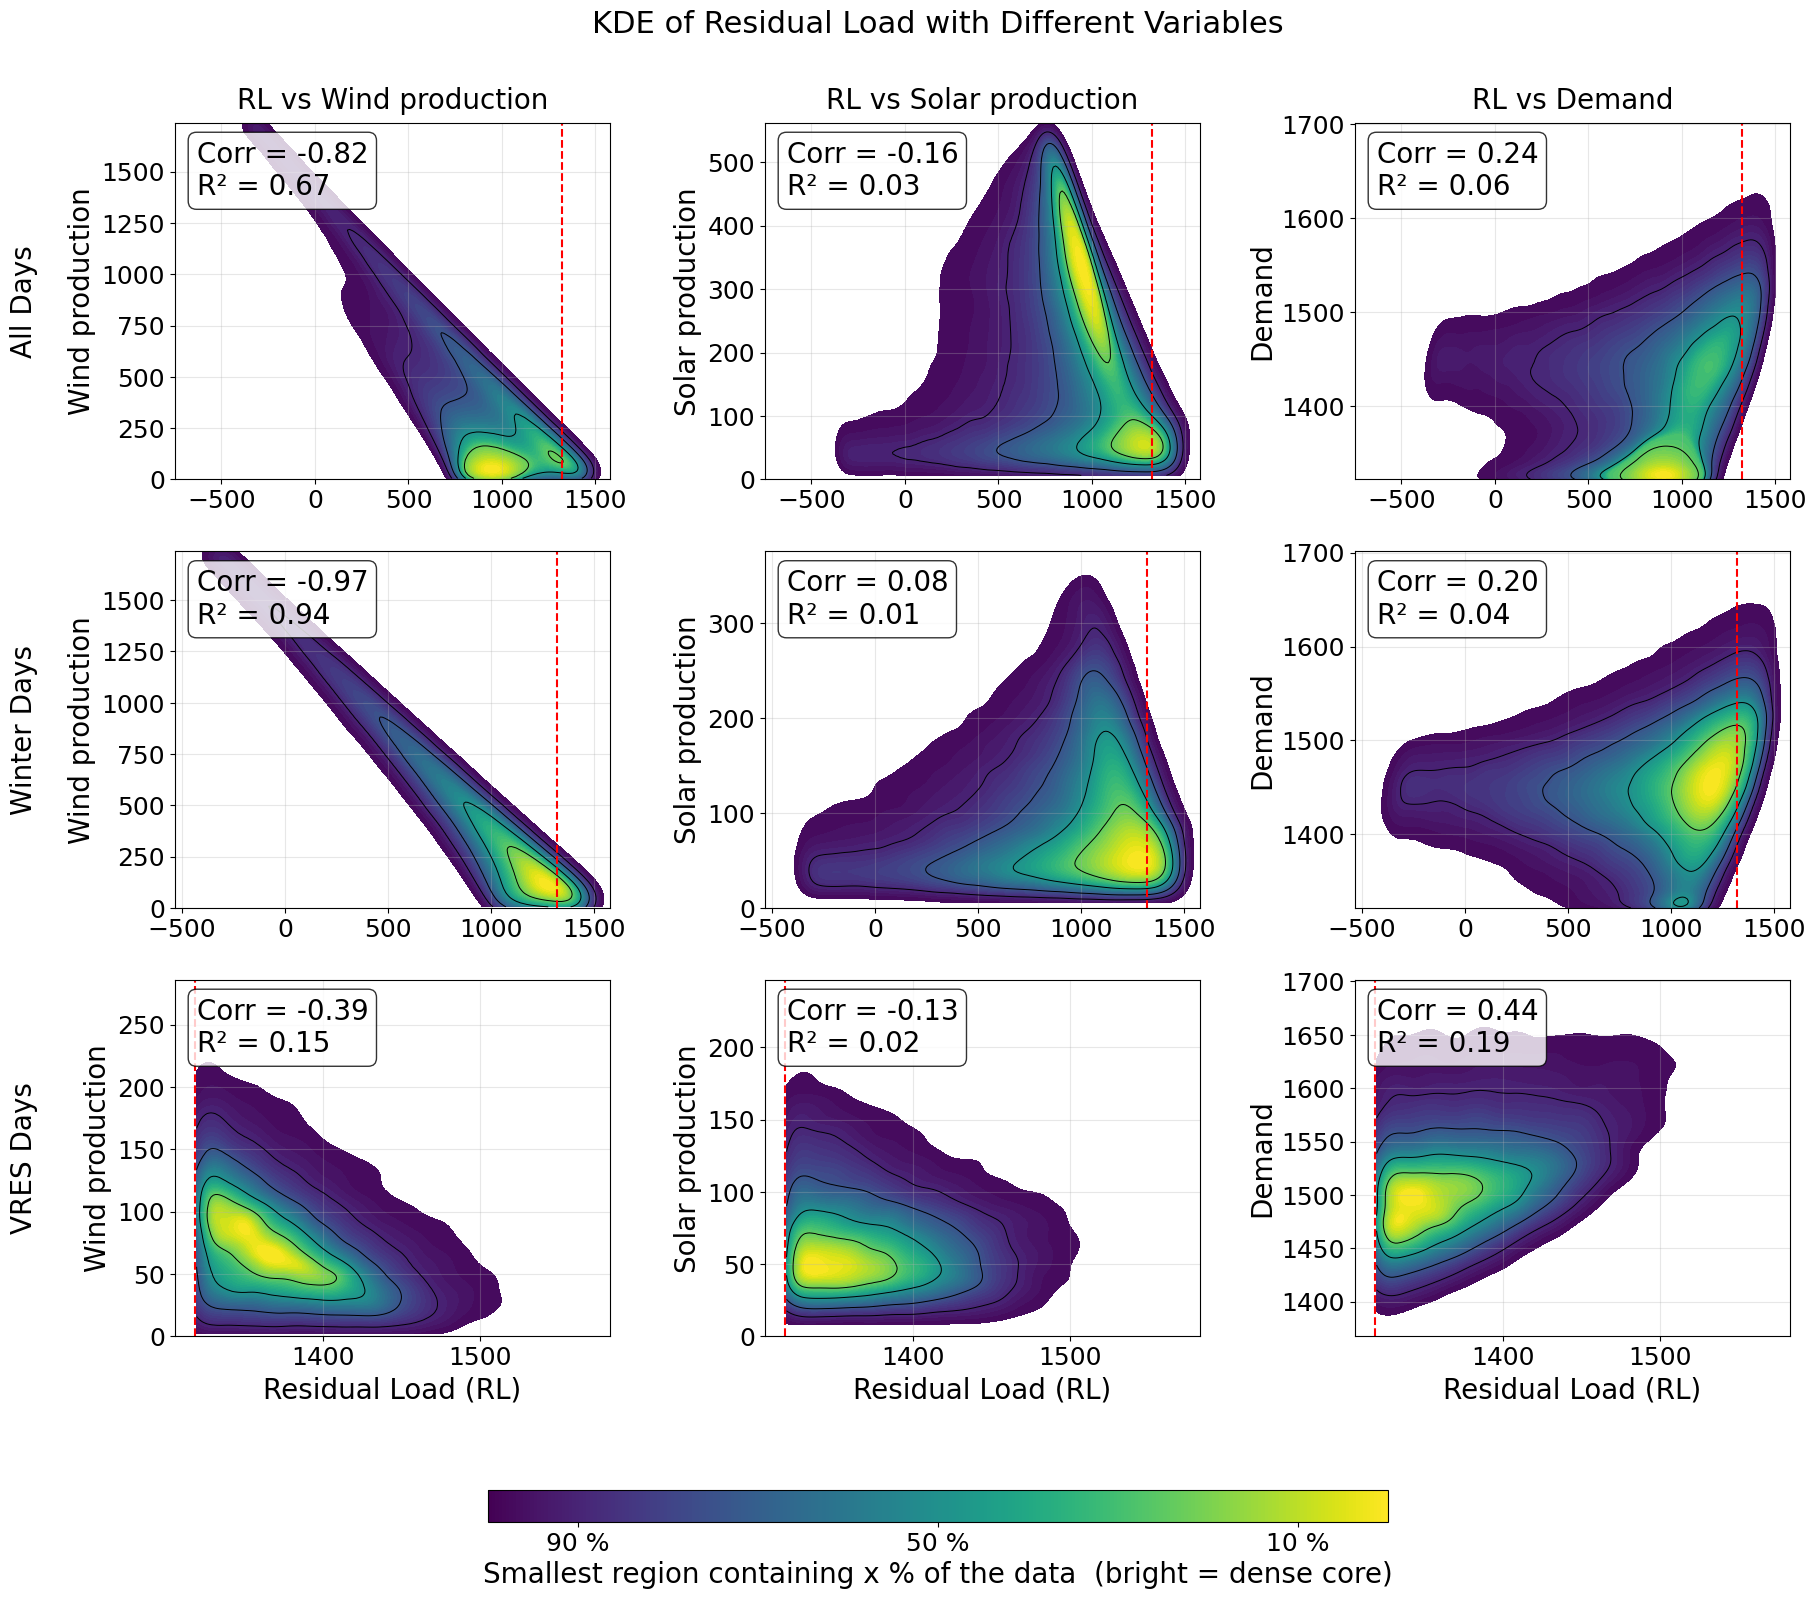

In [17]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.ndimage import gaussian_filter

mpl.rcParams.update({
    'font.size': 20, 'axes.titlesize': 22, 'axes.labelsize': 20,
    'xtick.labelsize': 18, 'ytick.labelsize': 18,
    'legend.fontsize': 20, 'figure.titlesize': 22,
})

FAST = False        # True = synthetic preview, False = your real data
MODE = 'hdr'       # 'hdr' = enclosed-probability colouring (shared, unit-free)
                   # 'absolute' = raw density on one shared scale (units differ by column)
CMAP = 'viridis'

variables = {'wind_total': 'Wind production',
             'solar_prod': 'Solar production',
             'demand':     'Demand'}


def make_fake_data(n=2000, seed=0):
    rng = np.random.default_rng(seed)
    def one(shift):
        rl = rng.normal(40 + shift, 15, n)
        return pd.DataFrame({
            'Residual_load': rl,
            'wind_total': np.abs(60 - 0.6 * rl + rng.normal(0, 12, n)),
            'solar_prod': np.abs(20 - 0.2 * rl + rng.normal(0, 8, n)),
            'demand':     80 + 0.3 * rl + rng.normal(0, 6, n),
        })
    return {'All Days': one(0), 'Winter Days': one(10), 'VRES Days': one(-10)}, 50.0


def kde2d(x, y, gridsize=200, bw_adjust=1.0):
    """Fast binned Gaussian KDE (Scott bandwidth, like seaborn). Returns xc, yc, Z[ny, nx]."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    n = len(x)
    f = n ** (-1 / 6) * bw_adjust                       # Scott's factor, d=2
    H, xe, ye = np.histogram2d(x, y, bins=gridsize,
                               range=[[x.min(), x.max()], [y.min(), y.max()]])
    dx, dy = xe[1] - xe[0], ye[1] - ye[0]
    Z = gaussian_filter(H, sigma=(x.std() * f / dx, y.std() * f / dy),
                        mode='constant') / (n * dx * dy)
    return 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1]), Z.T


def hdr_field(Z):
    """1 - (smallest probability mass of a region containing each cell).
    Core of the distribution -> ~1, outskirts -> ~0. Unit-free, comparable across panels."""
    flat = Z.ravel()
    order = np.argsort(-flat)
    cum = np.cumsum(flat[order]); cum /= cum[-1]
    H = np.empty_like(flat); H[order] = cum
    return 1 - H.reshape(Z.shape)


def make_figure(datasets, res_load_thresh, levels=50, gridsize=200, bw_adjust=1.0):
    # ---- pass 1: compute every density (fast) ----
    fields = {}
    for dname, d in datasets.items():
        for var in variables:
            xc, yc, Z = kde2d(d['Residual_load'], d[var], gridsize, bw_adjust)
            fields[(dname, var)] = (xc, yc, Z)

    if MODE == 'hdr':
        vmax = 1.0
        line_levels = [0.10, 0.25, 0.50, 0.75]          # 90/75/50/25 % regions
        cb_label = 'Smallest region containing x % of the data  (bright = dense core)'
        tick_pos, tick_lab = [0.10, 0.5, 0.90], ['90 %', '50 %', '10 %']
    else:
        vmax = max(Z.max() for _, _, Z in fields.values())
        line_levels = np.linspace(0, vmax, 10)[1:-1]
        cb_label = 'KDE density (units differ between columns)'
        tick_pos, tick_lab = None, None
    norm = Normalize(0, vmax)
    fill_levels = np.linspace(0.02 * vmax, vmax, levels)  # lowest 2 % not drawn (like thresh=0.02)

    # ---- pass 2: draw ----
    fig, axes = plt.subplots(3, 3, figsize=(18, 16))
    fig.suptitle('KDE of Residual Load with Different Variables')

    for r, (dname, d) in enumerate(datasets.items()):
        x = d['Residual_load']
        for c, (var, ylabel) in enumerate(variables.items()):
            ax = axes[r, c]
            xc, yc, Z = fields[(dname, var)]
            F = hdr_field(Z) if MODE == 'hdr' else Z

            ax.contourf(xc, yc, F, levels=fill_levels, cmap=CMAP, norm=norm)
            ax.contour(xc, yc, F, levels=line_levels, colors='black', linewidths=0.7)
            ax.axvline(res_load_thresh, color='red', ls='--', lw=1.5)
            if c != 2:
                ax.set_ylim(0, None)

            corr = np.corrcoef(x, d[var])[0, 1]
            ax.set_xlabel('Residual Load (RL)' if r == 2 else '')
            ax.set_ylabel(ylabel)
            ax.grid(True, alpha=0.3)
            ax.text(0.05, 0.95, f'Corr = {corr:.2f}\nR² = {corr**2:.2f}',
                    transform=ax.transAxes, va='top',
                    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    fig.tight_layout(rect=[0, 0.09, 1, 0.97])

    for r, name in enumerate(datasets):
        p = axes[r, 0].get_position()
        fig.text(0.0, (p.y0 + p.y1) / 2, name, va='center', ha='right', rotation=90)
    for c, ylabel in enumerate(variables.values()):
        p = axes[0, c].get_position()
        fig.text((p.x0 + p.x1) / 2, p.y1 + 0.005, f'RL vs {ylabel}', va='bottom', ha='center')

    # ---- ONE colourbar, same norm/cmap as every panel ----
    cax = fig.add_axes([0.25, 0.035, 0.5, 0.02])
    cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=CMAP), cax=cax, orientation='horizontal')
    cbar.set_label(cb_label)
    if tick_pos is not None:
        cbar.set_ticks(tick_pos); cbar.set_ticklabels(tick_lab)
    return fig


if FAST:
    datasets, thresh = make_fake_data()
else:
    datasets = {'All Days': df, 'Winter Days': df_winter, 'VRES Days': df_filtered}
    thresh = res_load_thresh

fig = make_figure(datasets, thresh, levels=50)
plt.savefig('/home/onennecke/Code/Figures/Correlations_RL_new.png', bbox_inches='tight', dpi=300)

# fig.savefig('kde_grid.png', dpi=300, bbox_inches='tight')
plt.show()

### Density curves

/tmp/ipykernel_3020049/2343498495.py:82: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(bottom=0.18)  # make room for the legend


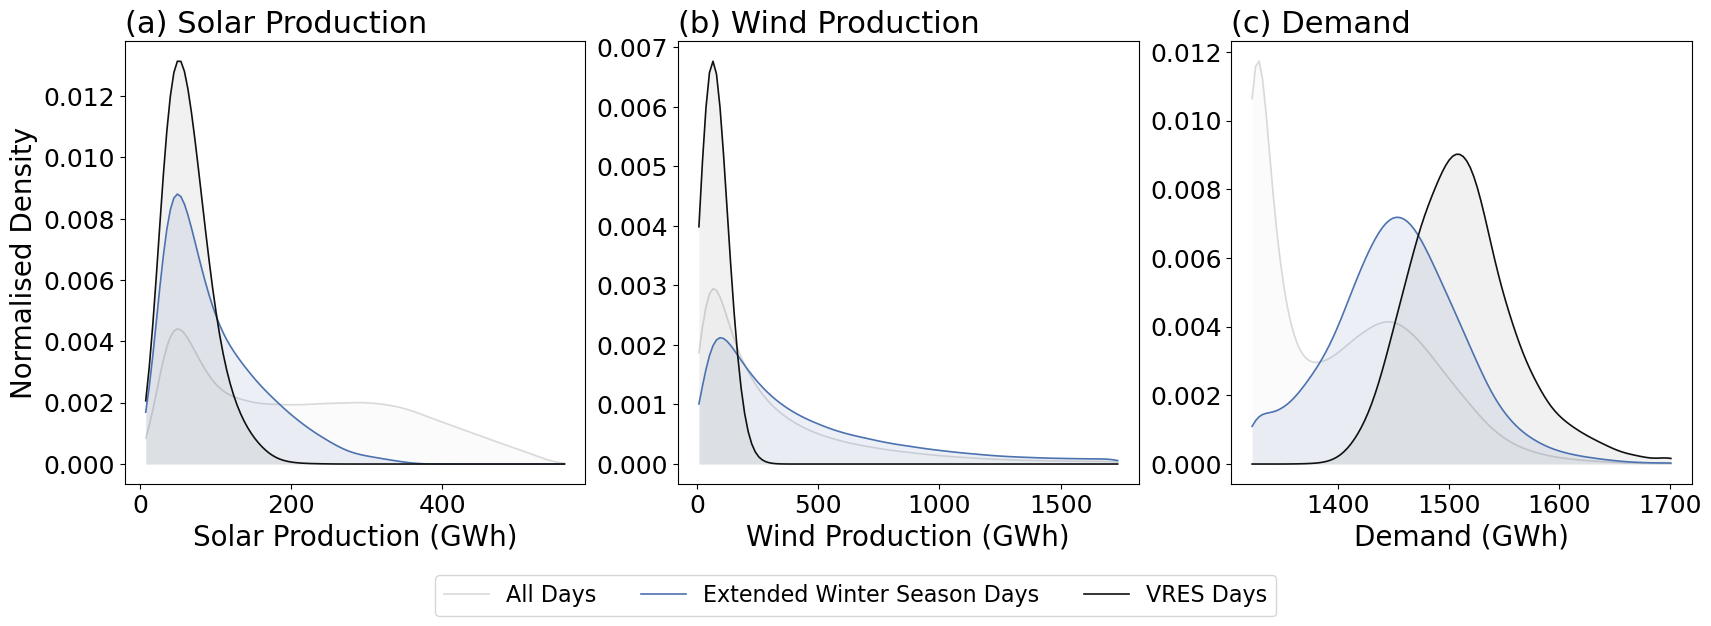

In [10]:
# variables and appearance
columns = [('solar_prod','(a) Solar Production', 'Solar Production (GWh)'), ('wind_total','(b) Wind Production', 'Wind Production (GWh)'), ('demand','(c) Demand', 'Demand (GWh)')]  # cols and pretty names
bins = 120  # number of histogram bins
smooth_sigma = 3  # smoothing bandwidth (larger = smoother)
figsize = (17,5.5)  # figure size
color_all, color_winter, color_filtered = '#d9d9d9','#4c72b0','#111111'  # colors
lw = 1.2  # line width
fill_alpha = 0.10  # fill transparency

# helper: gaussian kernel (precompute once) ------------------------------------------------
kernel_half = max(1, int(3*smooth_sigma))  # half-width of kernel
k_x = np.arange(-kernel_half, kernel_half+1)  # kernel x coords
kernel = np.exp(-0.5*(k_x/smooth_sigma)**2)  # gaussian weights
kernel = kernel / kernel.sum()  # normalize kernel to sum=1
# -----------------------------------------------------------------------------------------


# make text bigger (global)
mpl.rcParams.update({
    'font.size': 16+4,
    'axes.titlesize': 18+4,
    'axes.labelsize': 16+4,
    'xtick.labelsize': 14+4,
    'ytick.labelsize': 14+4,
    'legend.fontsize': 16+4,
    'figure.titlesize': 18+4,
})


fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True, sharey=False)  # 3 subplots in a row

for ax, (col, title, xaxis) in zip(axes, columns):
    a = df[col].values  # all data array
    w = df_winter[col].values  # winter array
    f = df_filtered[col].values  # filtered/high-RL array

    # common bin edges spanning min..max across all 3 sets so curves align
    combined_min = min(a.min(), w.min(), f.min())  # global min
    combined_max = max(a.max(), w.max(), f.max())  # global max
    edges = np.linspace(combined_min, combined_max, bins+1)  # bin edges
    centers = (edges[:-1] + edges[1:]) / 2.0  # bin centers

    # histogram densities (density=True -> density per unit)
    ca, _ = np.histogram(a, bins=edges, density=True)  # density for all
    cw, _ = np.histogram(w, bins=edges, density=True)  # density for winter
    cf, _ = np.histogram(f, bins=edges, density=True)  # density for filtered

    # smooth densities by convolving with the gaussian kernel
    sa = np.convolve(ca, kernel, mode='same')  # smoothed all
    sw = np.convolve(cw, kernel, mode='same')  # smoothed winter
    sf = np.convolve(cf, kernel, mode='same')  # smoothed filtered

    # normalize each curve to its own peak so every curve's max == 1
    # sa /= max(sa.max(), 1e-12)  # normalize all
    # sw /= max(sw.max(), 1e-12)  # normalize winter
    # sf /= max(sf.max(), 1e-12)  # normalize filtered

    # plotting curves + fills
    ax.plot(centers, sa, lw=lw, color=color_all, label='All', zorder=1)  # all curve
    ax.fill_between(centers, sa, 0, color=color_all, alpha=fill_alpha, linewidth=0)  # fill all

    ax.plot(centers, sw, lw=lw, color=color_winter, label='Winter', zorder=2)  # winter curve
    ax.fill_between(centers, sw, 0, color=color_winter, alpha=fill_alpha, linewidth=0)  # fill winter

    ax.plot(centers, sf, lw=lw, color=color_filtered, label='VRES', zorder=3)  # filtered curve
    ax.fill_between(centers, sf, 0, color=color_filtered, alpha=0.06, linewidth=0)  # fill filtered

    # labels and styling
    ax.set_title(title, loc='left')  # subplot title
    ax.set_xlabel(xaxis)  # x label
    if ax == axes[0]:
        ax.set_ylabel('Normalised Density')  # y label    ax.grid(True, linestyle=':', alpha=0.4)  # grid
    # ax.legend(fontsize='small')  # legend

# fig.suptitle('Smoothed distributions — All / Winter / VRES (each peak = 1)', y=1.04, fontsize=18)  # overall title

legend_handles = [
    Line2D([0], [0], color=color_all, lw=lw, label='All Days'),
    Line2D([0], [0], color=color_winter, lw=lw, label='Extended Winter Season Days'),
    Line2D([0], [0], color=color_filtered, lw=lw, label='VRES Days'),
]
fig.subplots_adjust(bottom=0.18)  # make room for the legend
fig.legend(handles=legend_handles, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.13), fontsize=16, frameon=True)

# plt.savefig('/home/onennecke/Code/Figures/Contr_RL_Days_dens_curves_0.png', bbox_inches='tight', dpi=300)

plt.show()  # display

### No density curves!

/tmp/ipykernel_3020049/152342486.py:82: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(bottom=0.18)  # make room for the legend


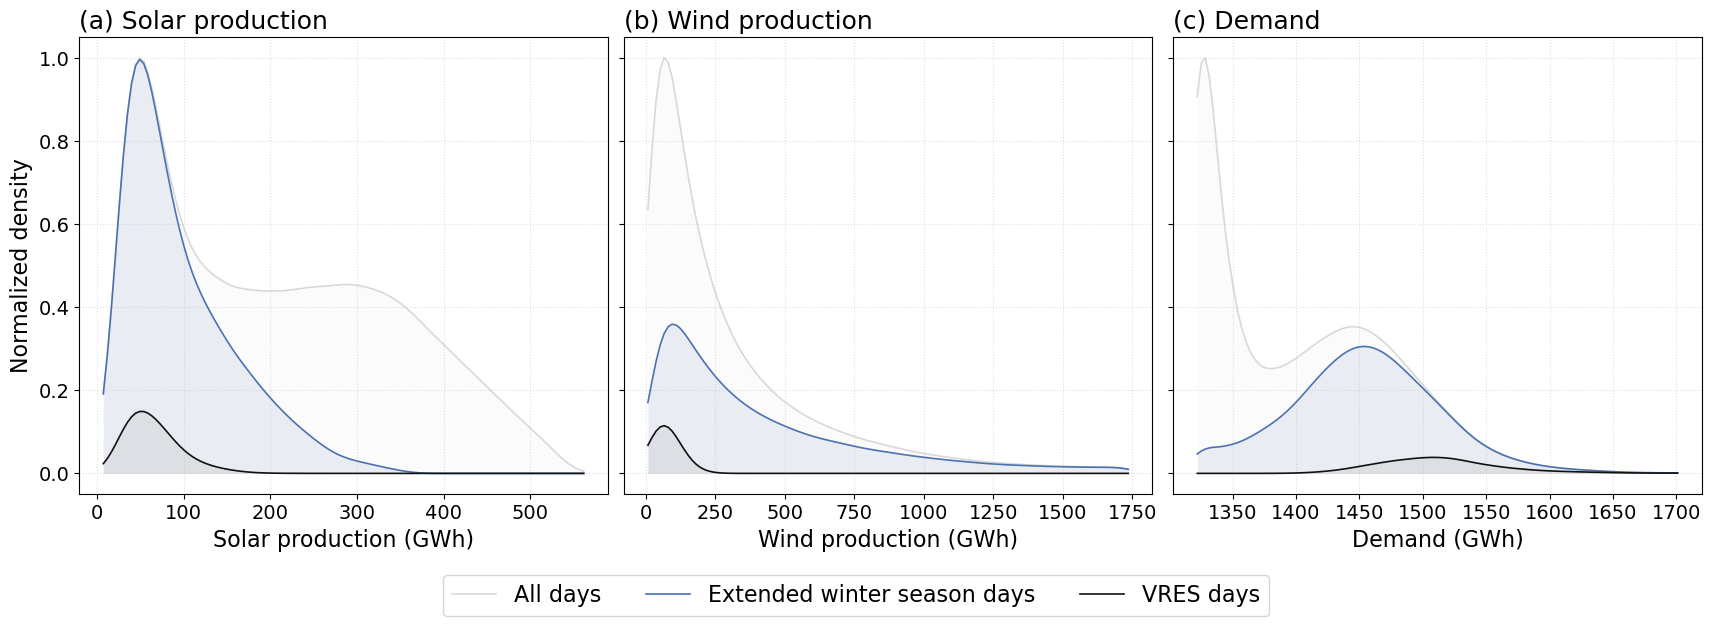

In [11]:
# variables and appearance
columns = [('solar_prod','(a) Solar production', 'Solar production (GWh)'), ('wind_total','(b) Wind production', 'Wind production (GWh)'), ('demand','(c) Demand', 'Demand (GWh)')]  # cols and pretty names
bins = 120  # number of histogram bins
smooth_sigma = 3  # smoothing bandwidth (larger = smoother)
figsize = (17,5.5)  # figure size
color_all, color_winter, color_filtered = '#d9d9d9','#4c72b0','#111111'  # colors
lw = 1.2  # line width
fill_alpha = 0.10  # fill transparency

# helper: gaussian kernel (precompute once) ------------------------------------------------
kernel_half = max(1, int(3*smooth_sigma))  # half-width of kernel
k_x = np.arange(-kernel_half, kernel_half+1)  # kernel x coords
kernel = np.exp(-0.5*(k_x/smooth_sigma)**2)  # gaussian weights
kernel = kernel / kernel.sum()  # normalize kernel to sum=1
# -----------------------------------------------------------------------------------------


# make text bigger (global)
mpl.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 16,
    'figure.titlesize': 18,
})

# plotting
fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True, sharey=True)  # 3 subplots in a row

for ax, (col, title, xaxis) in zip(axes, columns):
    a = df[col].values  # all data array
    w = df_winter[col].values  # winter array
    f = df_filtered[col].values  # filtered/high-RL array

    # common bin edges spanning min..max across all 3 sets so curves align
    combined_min = min(a.min(), w.min(), f.min())  # global min
    combined_max = max(a.max(), w.max(), f.max())  # global max
    edges = np.linspace(combined_min, combined_max, bins+1)  # bin edges
    centers = (edges[:-1] + edges[1:]) / 2.0  # bin centers

    # histogram counts (density=False -> raw counts) computed on the same edges
    ca, _ = np.histogram(a, bins=edges, density=False)  # counts for all
    cw, _ = np.histogram(w, bins=edges, density=False)  # counts for winter
    cf, _ = np.histogram(f, bins=edges, density=False)  # counts for filtered

    # smooth counts by convolving with the gaussian kernel
    sa = np.convolve(ca, kernel, mode='same')  # smoothed all
    sw = np.convolve(cw, kernel, mode='same')  # smoothed winter
    sf = np.convolve(cf, kernel, mode='same')  # smoothed filtered

    # normalize so the largest peak among the three equals 1 (same as your original)
    peak = max(sa.max(), sw.max(), sf.max(), 1e-12)  # avoid division by zero
    sa /= peak  # normalized all
    sw /= peak  # normalized winter
    sf /= peak  # normalized filtered

    # plotting curves + fills
    ax.plot(centers, sa, lw=lw, color=color_all, label='All', zorder=1)  # all curve
    ax.fill_between(centers, sa, 0, color=color_all, alpha=fill_alpha, linewidth=0)  # fill all

    ax.plot(centers, sw, lw=lw, color=color_winter, label='Winter', zorder=2)  # winter curve
    ax.fill_between(centers, sw, 0, color=color_winter, alpha=fill_alpha, linewidth=0)  # fill winter

    ax.plot(centers, sf, lw=lw, color=color_filtered, label='VRES', zorder=3)  # filtered curve
    ax.fill_between(centers, sf, 0, color=color_filtered, alpha=0.06, linewidth=0)  # fill filtered

    # labels and styling
    ax.set_title(title, loc='left')  # subplot title
    ax.set_xlabel(xaxis)  # x label
    if ax == axes[0]:
        ax.set_ylabel('Normalized density')  # y label
    ax.grid(True, linestyle=':', alpha=0.4)  # grid
    # ax.legend(fontsize='small')  # legend

legend_handles = [
    Line2D([0], [0], color=color_all, lw=lw, label='All days'),
    Line2D([0], [0], color=color_winter, lw=lw, label='Extended winter season days'),
    Line2D([0], [0], color=color_filtered, lw=lw, label='VRES days'),
]
fig.subplots_adjust(bottom=0.18)  # make room for the legend
fig.legend(handles=legend_handles, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.13), fontsize=16, frameon=True)

# slightly larger suptitle
# fig.suptitle('Smoothed distributions', y=1.04, fontsize=18)

# fig.suptitle('Smoothed distributions', y=1.04, fontsize=14)  # overall title

# plt.savefig('/home/onennecke/Code/Figures/Contr_RL_Days_dens_curves_1.png', bbox_inches='tight', dpi=300)

plt.show()  # display


Was bedeutet das:

1. Alle niedrigen Solarwerte sind im Winter
2. Es gibt keine VRES Tage mit hoher Sonnenproduktion, aber die ist auch nicht zwangsläufig ganz niedrig (Kurve wesentlich breiter als bei Wind)
3. Die Verteilung der VRES Tage hat ist ähnlich zu der winter Kurve (etwas verschoben) 
3. Beim Wind ist es anders herum, da sind alle hohen Werte im Winter, es gibt aber auch einige niedrige im Winter
4. Kein VRES Tag hat eine hohe Windproduktion
5. Demand Kurve mit allen Werten hat viele niedrige Werte, und einige in der Mitte
6. Alle Hohen sind im Winter
7. Die VRES Verteilung ist noch höher geshiftet als die des Winters, aber auch hier kommen mittlere Werte vor

/tmp/ipykernel_3020049/1610328488.py:83: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(bottom=0.18)  # make room for the legend


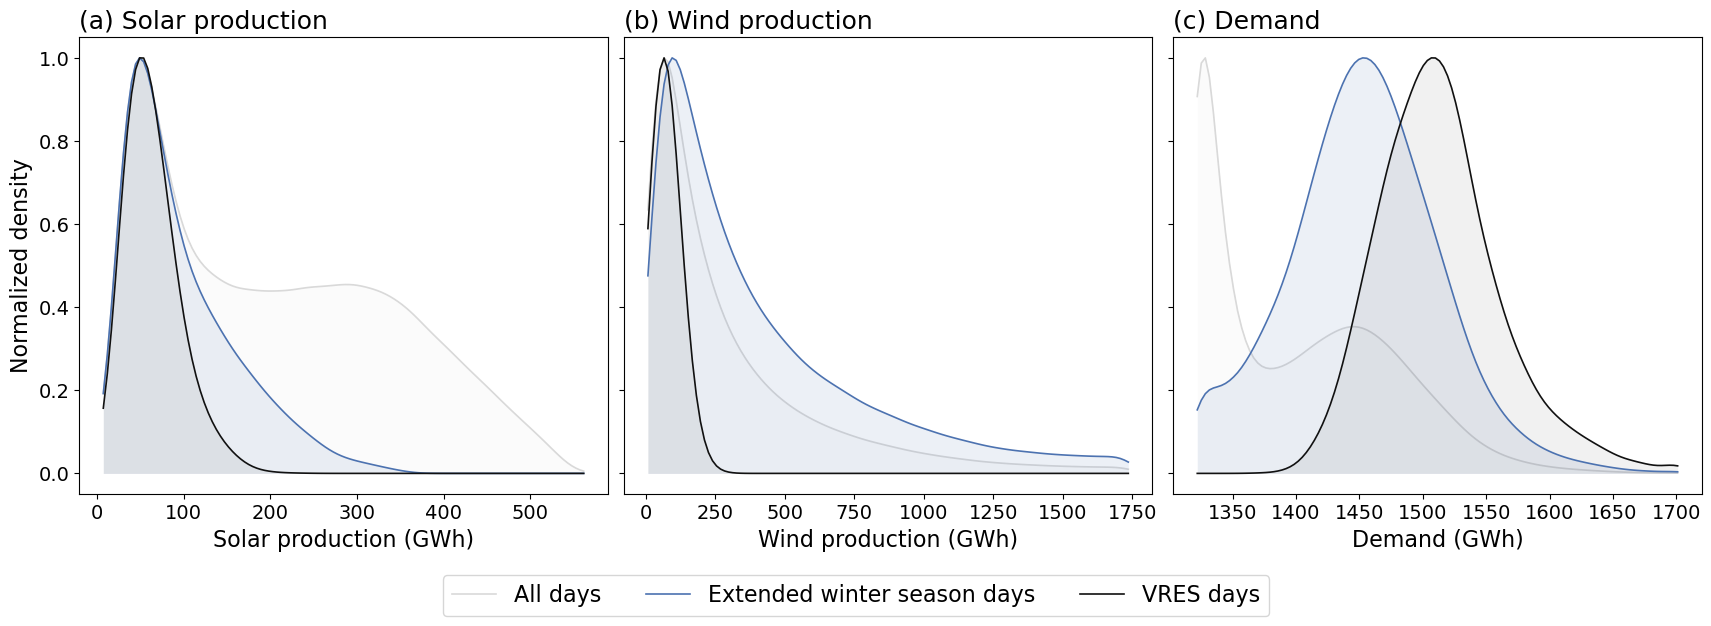

In [12]:
# variables and appearance
columns = [('solar_prod','(a) Solar production', 'Solar production (GWh)'), ('wind_total','(b) Wind production', 'Wind production (GWh)'), ('demand','(c) Demand', 'Demand (GWh)')]  # cols and pretty names
bins = 120  # number of histogram bins
smooth_sigma = 3  # smoothing bandwidth (larger = smoother)
figsize = (17,5.5)  # figure size
color_all, color_winter, color_filtered = '#d9d9d9','#4c72b0','#111111'  # colors
lw = 1.2  # line width
fill_alpha = 0.10  # fill transparency

# helper: gaussian kernel (precompute once) ------------------------------------------------
kernel_half = max(1, int(3*smooth_sigma))  # half-width of kernel
k_x = np.arange(-kernel_half, kernel_half+1)  # kernel x coords
kernel = np.exp(-0.5*(k_x/smooth_sigma)**2)  # gaussian weights
kernel = kernel / kernel.sum()  # normalize kernel to sum=1
# -----------------------------------------------------------------------------------------


# make text bigger (global)
mpl.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 16,
    'figure.titlesize': 18,
})


# plotting
fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True, sharey=True)  # 3 subplots in a row

for ax, (col, title, xaxis) in zip(axes, columns):
    a = df[col].values  # all data array
    w = df_winter[col].values  # winter array
    f = df_filtered[col].values  # filtered/high-RL array

    # common bin edges spanning min..max across all 3 sets so curves align
    combined_min = min(a.min(), w.min(), f.min())  # global min
    combined_max = max(a.max(), w.max(), f.max())  # global max
    edges = np.linspace(combined_min, combined_max, bins+1)  # bin edges
    centers = (edges[:-1] + edges[1:]) / 2.0  # bin centers

    # histogram densities (density=True -> density per unit)
    ca, _ = np.histogram(a, bins=edges, density=True)  # density for all
    cw, _ = np.histogram(w, bins=edges, density=True)  # density for winter
    cf, _ = np.histogram(f, bins=edges, density=True)  # density for filtered

    # smooth densities by convolving with the gaussian kernel
    sa = np.convolve(ca, kernel, mode='same')  # smoothed all
    sw = np.convolve(cw, kernel, mode='same')  # smoothed winter
    sf = np.convolve(cf, kernel, mode='same')  # smoothed filtered

    # normalize each curve to its own peak so every curve's max == 1
    sa /= max(sa.max(), 1e-12)  # normalize all
    sw /= max(sw.max(), 1e-12)  # normalize winter
    sf /= max(sf.max(), 1e-12)  # normalize filtered

    # plotting curves + fills
    ax.plot(centers, sa, lw=lw, color=color_all, label='All', zorder=1)  # all curve
    ax.fill_between(centers, sa, 0, color=color_all, alpha=fill_alpha, linewidth=0)  # fill all

    ax.plot(centers, sw, lw=lw, color=color_winter, label='Winter', zorder=2)  # winter curve
    ax.fill_between(centers, sw, 0, color=color_winter, alpha=fill_alpha, linewidth=0)  # fill winter

    ax.plot(centers, sf, lw=lw, color=color_filtered, label='VRES', zorder=3)  # filtered curve
    ax.fill_between(centers, sf, 0, color=color_filtered, alpha=0.06, linewidth=0)  # fill filtered

    # labels and styling
    ax.set_title(title, loc='left')  # subplot title
    ax.set_xlabel(xaxis)  # x label
    if ax == axes[0]:
        ax.set_ylabel('Normalized density')  # y label    ax.grid(True, linestyle=':', alpha=0.4)  # grid
    # ax.legend(fontsize='small')  # legend

# fig.suptitle('Smoothed distributions — All / Winter / VRES (each peak = 1)', y=1.04, fontsize=18)  # overall title

legend_handles = [
    Line2D([0], [0], color=color_all, lw=lw, label='All days'),
    Line2D([0], [0], color=color_winter, lw=lw, label='Extended winter season days'),
    Line2D([0], [0], color=color_filtered, lw=lw, label='VRES days'),
]
fig.subplots_adjust(bottom=0.18)  # make room for the legend
fig.legend(handles=legend_handles, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.13), fontsize=16, frameon=True)

# plt.savefig('/home/onennecke/Code/Figures/Contr_RL_Days_dens_curves_2.png', bbox_inches='tight', dpi=300)

plt.show()  # display


In [ ]:

# Filter by the threshold
df_filtered = df[df['Residual_load'] > res_load_thresh]

# Drop any remaining rows with NaNs across any column (optional, but you said "without nan values")
df_filtered = df_filtered.dropna(how='any').reset_index(drop=True)

In [24]:
df = df.loc[df['solar_prod'] != 0].dropna(how='any').reset_index(drop=True)
df_filtered = df_filtered.loc[df_filtered['solar_prod'] != 0].dropna(how='any').reset_index(drop=True)

/tmp/ipykernel_3020049/753834556.py:161: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  ax.scatter(
/tmp/ipykernel_3020049/753834556.py:176: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  ax.scatter(


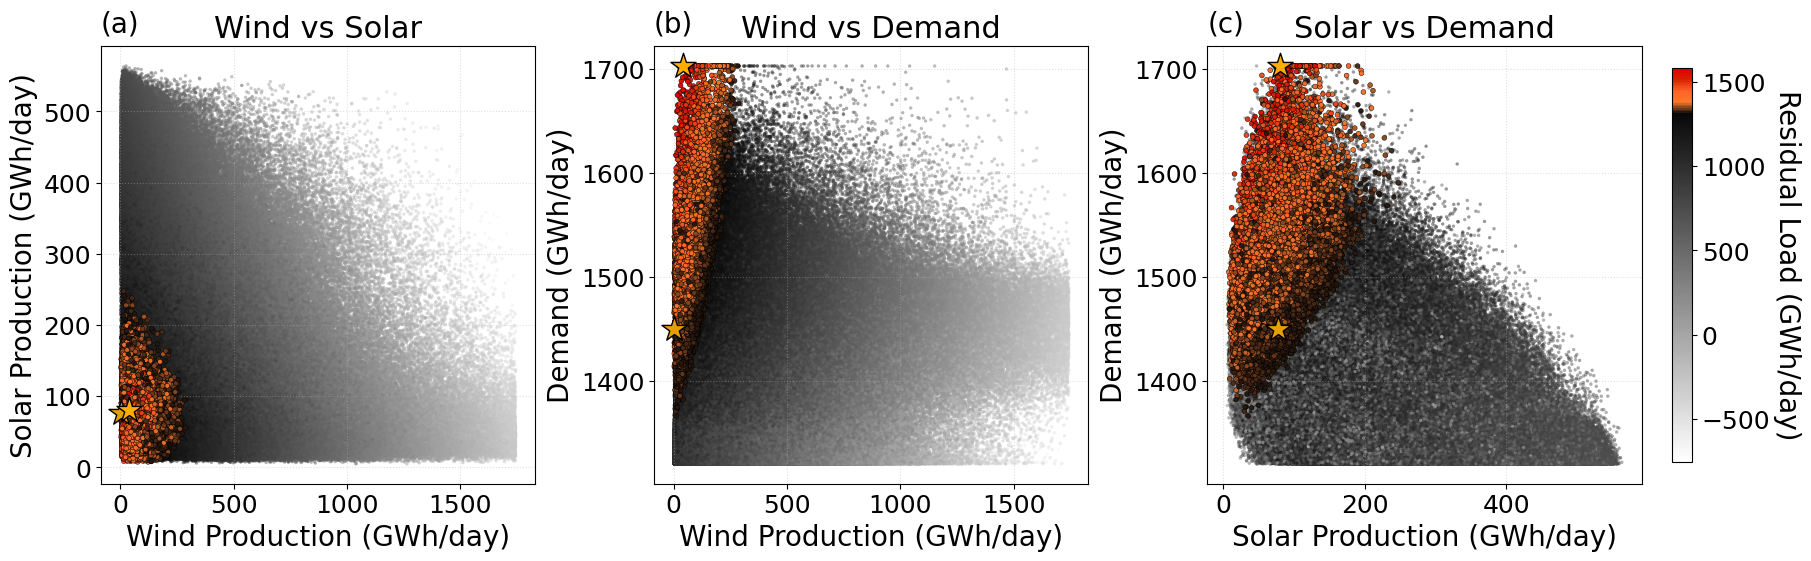

In [ ]:


mpl.rcParams.update({
    'font.size': 16+4,
    'axes.titlesize': 18+4,
    'axes.labelsize': 16+4,
    'xtick.labelsize': 14+4,
    'ytick.labelsize': 14+4,
    'legend.fontsize': 16+4,
    'figure.titlesize': 18+4,
})


# -------------- user parameters --------------
marker_all = 6
marker_filt = 12
alpha_all = 0.45
alpha_filt = 0.95
figsize = (18, 5.5)

# base colormaps you want to combine
cmap_low = plt.cm.binary        # used for the lower/majority range
# cmap_high = plt.cm.gist_heat_r  # used only for the top portion
# orig = plt.cm.gist_heat_r
# colors = orig(np.linspace(0.0, 1.0, 256))
# # replace the darkest color with a dark red (hex chosen here)
# colors[-1] = mcolors.to_rgba("#bb0000")
# cmap_high = mcolors.LinearSegmentedColormap.from_list('gist_heat_r_darkred_end', colors)

# cmap_high = plt.cm.get_cmap('YlOrRd')  # less custom but also avoids black
cmap_high = mcolors.LinearSegmentedColormap.from_list(
    'yellow_orange_darkred',
    ["#fe8f4f", "#fe7729", "#fe6529", "#d92101", "#df0000"]  # light yellow -> orange -> dark red
)


# fraction of the colormap to reserve for cmap_high (top of the scale)
upper_frac = 0.05   # 0.05 -> top 5% of colors come from cmap_high

# number of discrete colors in combined map (higher -> smoother)
ncolors = 256

# seam blending width in colors (to smooth transition); small integer like 6..12
blend = 8
# ----------------------------------------------

# ------------------ Replace previous colormap-building with this ------------------
# threshold in original Residual_load units (set to the value you want)
threshold = 1319.1588066525014
# 1398.1161147066591  # <- change this to your desired threshold

# ensure vmin/vmax are available (if not, derive from combined df + df_filtered)
if 'vmin' not in globals() or 'vmax' not in globals():
    c_pool = np.concatenate([
        df['Residual_load'].to_numpy().ravel(),
        df_filtered['Residual_load'].to_numpy().ravel()
    ])
    c_pool = c_pool[np.isfinite(c_pool)]
    if c_pool.size == 0:
        raise RuntimeError("No finite Residual_load values found in df / df_filtered.")
    vmin, vmax = np.nanmin(c_pool), np.nanmax(c_pool)

# compute upper_frac from threshold relative to the vmin..vmax range
# if threshold >= vmax -> upper_frac = 0 (no high-colormap)
# if threshold <= vmin -> upper_frac = 1 (all high-colormap)
if vmax <= vmin:
    upper_frac = 0.5  # fallback if degenerate range
else:
    upper_frac = (vmax - threshold) / (vmax - vmin)
    upper_frac = float(np.clip(upper_frac, 0.0, 1.0))

# --- optional alternative: compute fraction based on empirical proportion of points above threshold
# uncomment to use empirical fraction (may be preferable if distribution is skewed)
# c_pool_vals = c_pool  # from above
# upper_frac = np.mean(c_pool_vals >= threshold)

# convert fraction to discrete color counts
n_high = max(2, int(round(upper_frac * ncolors)))
n_low = max(2, ncolors - n_high)
# ensure exact total
if n_low + n_high != ncolors:
    n_low = ncolors - n_high

# sample the two colormaps
colors_low = cmap_low(np.linspace(0.0, 1.0, n_low))
colors_high = cmap_high(np.linspace(0.0, 1.0, n_high))

# create a blended seam to avoid a hard cut (uses `blend` from your config)
if blend > 0:
    b = min(blend, n_low - 1, n_high - 1)
    if b > 0:
        seam_low = colors_low[-b:]
        seam_high = colors_high[:b]
        blended = np.array([ (1 - t) * sl + t * sh for t, sl, sh in zip(np.linspace(0,1,b), seam_low, seam_high) ])
        colors = np.vstack([colors_low[:-b], blended, colors_high[b:]])
    else:
        colors = np.vstack([colors_low, colors_high])
else:
    colors = np.vstack([colors_low, colors_high])

# final combined colormap
combined_cmap = mcolors.LinearSegmentedColormap.from_list("combined_top_threshold", colors)
# -----------------------------------------------------------------------------------


# plotting pairs
pairs = [
    ('wind_total', 'solar_prod', 'Wind Production (GWh/day)', 'Solar Production (GWh/day)', 'Wind vs Solar'),
    ('wind_total', 'demand', 'Wind Production (GWh/day)', 'Demand (GWh/day)', 'Wind vs Demand'),
    ('solar_prod', 'demand', 'Solar Production (GWh/day)', 'Demand (GWh/day)', 'Solar vs Demand'),
]

# determine shared vmin/vmax from both dataframes (no scaling)
c_pool = np.concatenate([
    df['Residual_load'].to_numpy().ravel(),
    df_filtered['Residual_load'].to_numpy().ravel()
])
c_pool = c_pool[np.isfinite(c_pool)]
if c_pool.size == 0:
    raise RuntimeError("No finite Residual_load values in df / df_filtered.")
vmin, vmax = np.nanmin(c_pool), np.nanmax(c_pool)

# create figure and axes
fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True, sharey=False)

for ax, (xcol, ycol, xlabel, ylabel, title) in zip(axes, pairs):
    # background: df
    x_all = df[xcol].to_numpy()
    y_all = df[ycol].to_numpy()
    c_all = df['Residual_load'].to_numpy()
    mask_all = np.isfinite(x_all) & np.isfinite(y_all) & np.isfinite(c_all)
    sc_all = ax.scatter(
        x_all[mask_all], y_all[mask_all],
        c=c_all[mask_all],
        cmap=combined_cmap,
        s=marker_all,
        alpha=alpha_all,
        vmin=vmin, vmax=vmax,
        edgecolors='none', zorder=1
    )
    
    # foreground: df_filtered
    x_f = df_filtered[xcol].to_numpy()
    y_f = df_filtered[ycol].to_numpy()
    c_f = df_filtered['Residual_load'].to_numpy()
    mask_f = np.isfinite(x_f) & np.isfinite(y_f) & np.isfinite(c_f)
    sc_f = ax.scatter(
        x_f[mask_f], y_f[mask_f],
        c=c_f[mask_f],
        cmap=combined_cmap,
        s=marker_filt,
        alpha=alpha_filt,
        vmin=vmin, vmax=vmax,
        edgecolors='black', linewidths=0.35, zorder=3
    )
    # ax.set_xlim(min(df['solar_prod'].min(), df['wind_total'].min(), df['demand'].min()), max(df['solar_prod'].max(), df['wind_total'].max(), df['demand'].max()))
    # ax.set_ylim(min(df['solar_prod'].min(), df['wind_total'].min(), df['demand'].min()), max(df['solar_prod'].max(), df['wind_total'].max(), df['demand'].max()))

    # # Set star marker at df_filtered_CS
    # x_cs = df_filtered_CS[xcol].to_numpy()
    # y_cs = df_filtered_CS[ycol].to_numpy()
    # # c_cs = df_filtered_CS['Residual_load'].to_numpy()
    # ax.scatter(
    #     x_cs, y_cs,
    #     c="#E69F00",
    #     cmap=combined_cmap,
    #     s=marker_filt * 30,
    #     alpha=1.0,
    #     vmin=vmin, vmax=vmax,
    #     edgecolors='black', linewidths=1.0,
    #     marker='*',
    #     zorder=4
    # )

    # x_cs = df_filtered_CS_extreme[xcol].to_numpy()
    # y_cs = df_filtered_CS_extreme[ycol].to_numpy()
    # # c_cs = df_filtered_CS['Residual_load'].to_numpy()
    # ax.scatter(
    #     x_cs, y_cs,
    #     c="#FFAE00",
    #     cmap=combined_cmap,
    #     s=marker_filt * 30,
    #     alpha=1.0,
    #     vmin=vmin, vmax=vmax,
    #     edgecolors='black', linewidths=1.0,
    #     marker='*',
    #     zorder=4
    # )
    

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, linestyle=':', alpha=0.4)

    # # simple legend for roles (not color)
    # legend_elements = [
    #     Line2D([0], [0], marker='o', color='w', label='All days',
    #            markerfacecolor='gray', markersize=7, alpha=alpha_all),
    #     Line2D([0], [0], marker='o', color='w', label='Filtered / VRES',
    #            markerfacecolor='gray', markeredgecolor='k', markersize=10, alpha=alpha_filt)
    # ]
    # ax.legend(handles=legend_elements, loc='upper right')

# left-aligned, not bold, placed just above each subplot
for i, ax in enumerate(axes):
    label = f'({chr(ord("a") + i)})'
    # y slightly above the axis (1.02); use va='bottom' so text sits above the top edge
    ax.text(0.0, 1.02, label,
            transform=ax.transAxes,
            fontweight='normal',  # not bold
            ha='left',
            va='bottom')

# single shared colorbar (maps numeric RL values to the combined colormap)
mappable = plt.cm.ScalarMappable(cmap=combined_cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
mappable.set_array([])
cbar = fig.colorbar(mappable, ax=axes.ravel().tolist(), shrink=0.9, pad=0.02)
cbar.set_label('Residual Load (GWh/day)', rotation=270, labelpad=22)

# Save plot
# plt.savefig('/home/onennecke/Code/Figures/Sctrplt_composition_marker.png', bbox_inches='tight', dpi=300)
# plt.savefig('/home/onennecke/Code/Figures/Sctrplt_composition_poster.png', bbox_inches='tight', dpi=300)

plt.show()


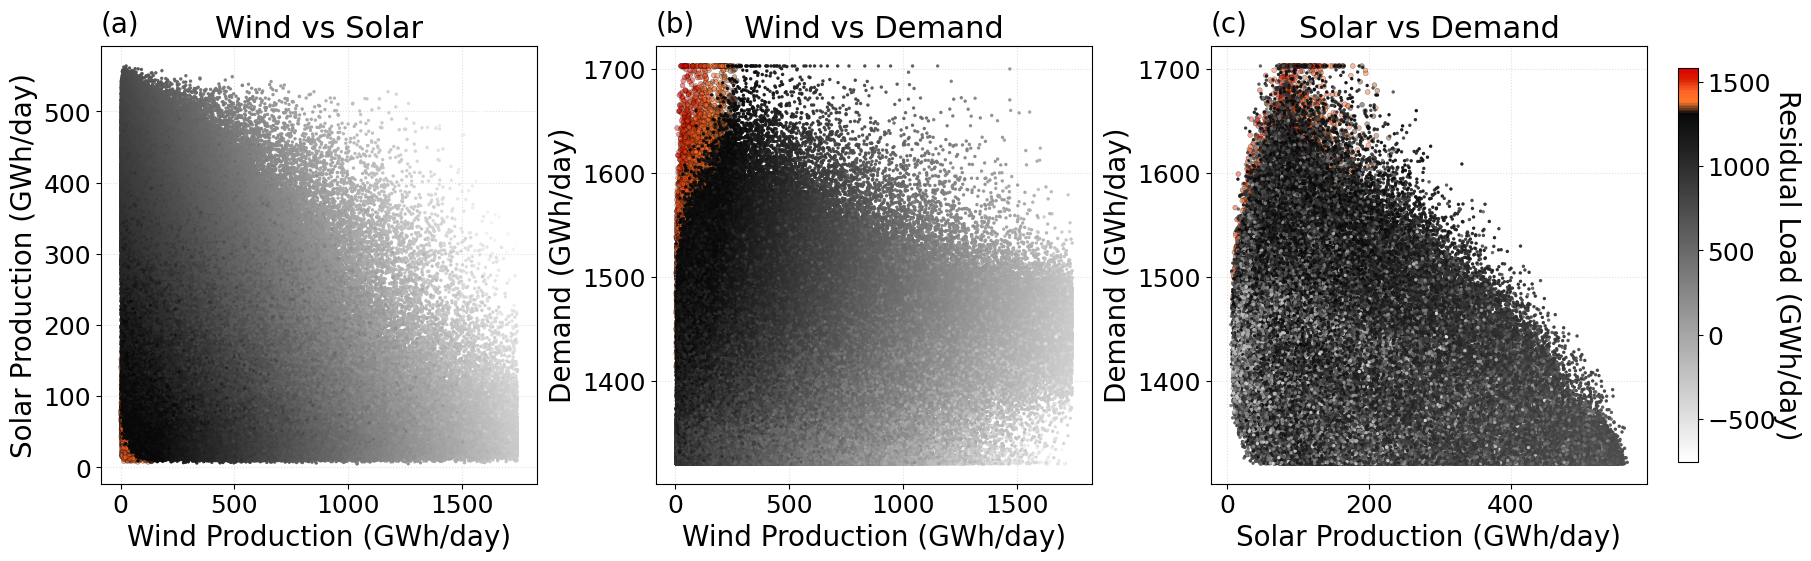

In [28]:

# -------------- user parameters --------------
marker_all = 12
marker_filt = 6
alpha_all = 0.45
alpha_filt = 0.95
figsize = (18, 5.5)

# base colormaps you want to combine
cmap_low = plt.cm.binary        # used for the lower/majority range
# cmap_high = plt.cm.gist_heat_r  # used only for the top portion
# orig = plt.cm.gist_heat_r
# colors = orig(np.linspace(0.0, 1.0, 256))
# # replace the darkest color with a dark red (hex chosen here)
# colors[-1] = mcolors.to_rgba("#bb0000")
# cmap_high = mcolors.LinearSegmentedColormap.from_list('gist_heat_r_darkred_end', colors)

# cmap_high = plt.cm.get_cmap('YlOrRd')  # less custom but also avoids black
cmap_high = mcolors.LinearSegmentedColormap.from_list(
    'yellow_orange_darkred',
    ["#fe8f4f", "#fe7729", "#fe6529", "#d92101", "#df0000"]  # light yellow -> orange -> dark red
)


# fraction of the colormap to reserve for cmap_high (top of the scale)
upper_frac = 0.05   # 0.05 -> top 5% of colors come from cmap_high

# number of discrete colors in combined map (higher -> smoother)
ncolors = 256

# seam blending width in colors (to smooth transition); small integer like 6..12
blend = 8
# ----------------------------------------------

# ------------------ Replace previous colormap-building with this ------------------
# threshold in original Residual_load units (set to the value you want)
threshold = 1319.1588066525014
# 1398.1161147066591  # <- change this to your desired threshold

# ensure vmin/vmax are available (if not, derive from combined df + df_reverse_filtered)
if 'vmin' not in globals() or 'vmax' not in globals():
    c_pool = np.concatenate([
        df_filtered['Residual_load'].to_numpy().ravel(),
        df_reverse_filtered['Residual_load'].to_numpy().ravel()
    ])
    c_pool = c_pool[np.isfinite(c_pool)]
    if c_pool.size == 0:
        raise RuntimeError("No finite Residual_load values found in df / df_reverse_filtered.")
    vmin, vmax = np.nanmin(c_pool), np.nanmax(c_pool)

# compute upper_frac from threshold relative to the vmin..vmax range
# if threshold >= vmax -> upper_frac = 0 (no high-colormap)
# if threshold <= vmin -> upper_frac = 1 (all high-colormap)
if vmax <= vmin:
    upper_frac = 0.5  # fallback if degenerate range
else:
    upper_frac = (vmax - threshold) / (vmax - vmin)
    upper_frac = float(np.clip(upper_frac, 0.0, 1.0))

# --- optional alternative: compute fraction based on empirical proportion of points above threshold
# uncomment to use empirical fraction (may be preferable if distribution is skewed)
# c_pool_vals = c_pool  # from above
# upper_frac = np.mean(c_pool_vals >= threshold)

# convert fraction to discrete color counts
n_high = max(2, int(round(upper_frac * ncolors)))
n_low = max(2, ncolors - n_high)
# ensure exact total
if n_low + n_high != ncolors:
    n_low = ncolors - n_high

# sample the two colormaps
colors_low = cmap_low(np.linspace(0.0, 1.0, n_low))
colors_high = cmap_high(np.linspace(0.0, 1.0, n_high))

# create a blended seam to avoid a hard cut (uses `blend` from your config)
if blend > 0:
    b = min(blend, n_low - 1, n_high - 1)
    if b > 0:
        seam_low = colors_low[-b:]
        seam_high = colors_high[:b]
        blended = np.array([ (1 - t) * sl + t * sh for t, sl, sh in zip(np.linspace(0,1,b), seam_low, seam_high) ])
        colors = np.vstack([colors_low[:-b], blended, colors_high[b:]])
    else:
        colors = np.vstack([colors_low, colors_high])
else:
    colors = np.vstack([colors_low, colors_high])

# final combined colormap
combined_cmap = mcolors.LinearSegmentedColormap.from_list("combined_top_threshold", colors)
# -----------------------------------------------------------------------------------


# plotting pairs
pairs = [
    ('wind_total', 'solar_prod', 'Wind Production (GWh/day)', 'Solar Production (GWh/day)', 'Wind vs Solar'),
    ('wind_total', 'demand', 'Wind Production (GWh/day)', 'Demand (GWh/day)', 'Wind vs Demand'),
    ('solar_prod', 'demand', 'Solar Production (GWh/day)', 'Demand (GWh/day)', 'Solar vs Demand'),
]

# determine shared vmin/vmax from both dataframes (no scaling)
c_pool = np.concatenate([
    df_filtered['Residual_load'].to_numpy().ravel(),
    df_reverse_filtered['Residual_load'].to_numpy().ravel()
])
c_pool = c_pool[np.isfinite(c_pool)]
if c_pool.size == 0:
    raise RuntimeError("No finite Residual_load values in df / df_reverse_filtered.")
vmin, vmax = np.nanmin(c_pool), np.nanmax(c_pool)

# create figure and axes
fig, axes = plt.subplots(1, 3, figsize=figsize, constrained_layout=True, sharey=False)

for ax, (xcol, ycol, xlabel, ylabel, title) in zip(axes, pairs):
    # background: df
    x_all = df_filtered[xcol].to_numpy()
    y_all = df_filtered[ycol].to_numpy()
    c_all = df_filtered['Residual_load'].to_numpy()
    mask_all = np.isfinite(x_all) & np.isfinite(y_all) & np.isfinite(c_all)
    sc_all = ax.scatter(
        x_all[mask_all], y_all[mask_all],
        c=c_all[mask_all],
        cmap=combined_cmap,
        s=marker_all,
        alpha=alpha_all,
        vmin=vmin, vmax=vmax,
        edgecolors='black', linewidths=0.35, zorder=1
    )

    # foreground: df_reverse_filtered
    x_f = df_reverse_filtered[xcol].to_numpy()
    y_f = df_reverse_filtered[ycol].to_numpy()
    c_f = df_reverse_filtered['Residual_load'].to_numpy()
    mask_f = np.isfinite(x_f) & np.isfinite(y_f) & np.isfinite(c_f)
    sc_f = ax.scatter(
        x_f[mask_f], y_f[mask_f],
        c=c_f[mask_f],
        cmap=combined_cmap,
        s=marker_filt,
        alpha=alpha_filt,
        vmin=vmin, vmax=vmax,
        edgecolors='none', zorder=3
    )
    # ax.set_xlim(min(df_filtered['solar_prod'].min(), df_filtered['wind_total'].min(), df_filtered['demand'].min()), max(df_filtered['solar_prod'].max(), df_filtered['wind_total'].max(), df_filtered['demand'].max()))
    # ax.set_ylim(min(df_filtered['solar_prod'].min(), df_filtered['wind_total'].min(), df_filtered['demand'].min()), max(df_filtered['solar_prod'].max(), df_filtered['wind_total'].max(), df_filtered['demand'].max()))

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, linestyle=':', alpha=0.4)

    # # simple legend for roles (not color)
    # legend_elements = [
    #     Line2D([0], [0], marker='o', color='w', label='All days',
    #            markerfacecolor='gray', markersize=7, alpha=alpha_all),
    #     Line2D([0], [0], marker='o', color='w', label='Filtered / VRES',
    #            markerfacecolor='gray', markeredgecolor='k', markersize=10, alpha=alpha_filt)
    # ]
    # ax.legend(handles=legend_elements, loc='upper right')

# left-aligned, not bold, placed just above each subplot
for i, ax in enumerate(axes):
    label = f'({chr(ord("a") + i)})'
    # y slightly above the axis (1.02); use va='bottom' so text sits above the top edge
    ax.text(0.0, 1.02, label,
            transform=ax.transAxes,
            fontweight='normal',  # not bold
            ha='left',
            va='bottom')

# single shared colorbar (maps numeric RL values to the combined colormap)
mappable = plt.cm.ScalarMappable(cmap=combined_cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))
mappable.set_array([])
cbar = fig.colorbar(mappable, ax=axes.ravel().tolist(), shrink=0.9, pad=0.02)
cbar.set_label('Residual Load (GWh/day)', rotation=270, labelpad=18)

# Save plot
# plt.savefig('/home/onennecke/Code/Figures/Sctrplt_composition_reverse.png', bbox_inches='tight', dpi=300)

plt.show()
